# Multivariable Linear Regression: Iris Sepal Width Prediction

**Machine Learning Algorithm:** Multivariable Linear Regression  
**Learning Type:** Supervised Learning  
**Problem Type:** Multivariable Linear Regression  
**Dataset:** Iris_Data_Set.csv  
**Target Variable:** SepalWidthCm

### Project Objective

The objective of this project is to develop a Multivariable Linear Regression model to predict the sepal width of an iris flower using its sepal length, petal length, and petal width.

The model will learn the relationships between multiple numerical features and use them to estimate the sepal width of previously unseen observations.

Import libraries 

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.linear_model import LinearRegression

print("All libraries are imported successfully")

All libraries are imported successfully


Load the Dataset

In [16]:
df=pd.read_csv(r"C:\Users\ASUS\OneDrive\Desktop\Aditya project\AI-ML-Algorithms\Datasets\Iris_Data_Set.csv")

Inspect the Dataset

In [17]:
print(df.head())
print(df.tail())


   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
      Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  \
145  146            6.7           3.0            5.2           2.3   
146  147            6.3           2.5            5.0           1.9   
147  148            6.5           3.0            5.2           2.0   
148  149            6.2           3.4            5.4           2.3   
149  150            5.9           3.0            5.1           1.8   

            Species  
145  Iris-virginica  
146  Iris-virginica  
147  Iris-virginica  
148  Iris-virginica  
149  Ir

In [5]:
print("The size of Dataset                    :",df.shape)
print("The number of column of the Dataset is :",df.shape[1])
print("The size of of row of the Dataset is   :",df.shape[0])

The size of Dataset                    : (150, 6)
The number of column of the Dataset is : 6
The size of of row of the Dataset is   : 150


In [7]:
print(df.columns.to_list())

['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


In [9]:
print(df.describe())

               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000      0.100000
25%     38.250000       5.100000      2.800000       1.600000      0.300000
50%     75.500000       5.800000      3.000000       4.350000      1.300000
75%    112.750000       6.400000      3.300000       5.100000      1.800000
max    150.000000       7.900000      4.400000       6.900000      2.500000


In [10]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB
None


Check the missing and duplicate values

In [12]:
print("The number of missing values :")
print(df.isnull().sum())

print("The number of duplicated values :")
print(df.duplicated().sum())

The number of missing values :
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64
The number of duplicated values :
0


Clear the dataset

In [18]:
df=df[["SepalLengthCm","SepalWidthCm","PetalLengthCm","PetalWidthCm"]].copy()

df["SepalLengthCm"]=pd.to_numeric(df["SepalLengthCm"],errors="coerce")
df["SepalWidthCm"]=pd.to_numeric(df["SepalWidthCm"],errors="coerce")
df["PetalLengthCm"]=pd.to_numeric(df["PetalLengthCm"],errors="coerce")
df["PetalWidthCm"]=pd.to_numeric(df["PetalWidthCm"],errors="coerce")

df=df.dropna()
df=df.drop_duplicates()


df=df.reset_index(drop=True)

df.head()


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [21]:
print("After cleaning the shape of the datset :",df.shape)
print("After cleaning the num of the missing values of the datset :")
print(df.isna().sum())

After cleaning the shape of the datset : (147, 4)
After cleaning the num of the missing values of the datset :
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
dtype: int64


Exploratory Data Analysis (EDA)

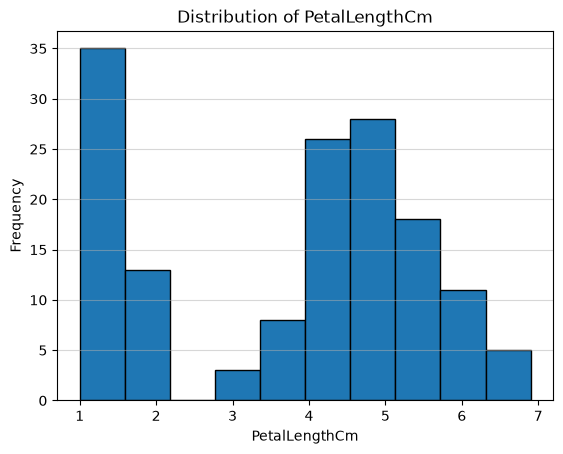

In [22]:
plt.Figure(figsize=(10,8))

plt.hist(df["PetalLengthCm"],bins=10,edgecolor="black")

plt.title("Distribution of PetalLengthCm")
plt.xlabel("PetalLengthCm")
plt.ylabel("Frequency")

plt.grid(axis="y",alpha=0.5)
plt.show()

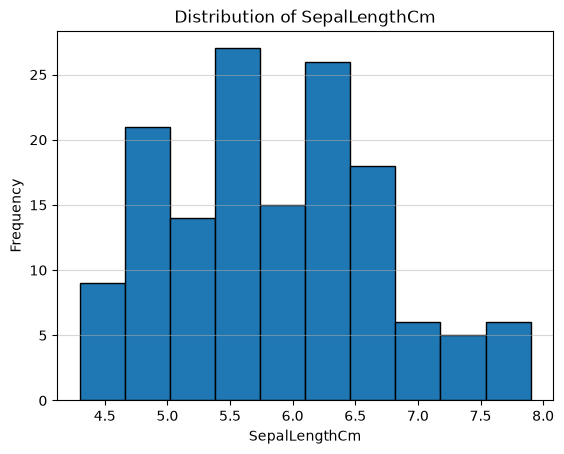

In [23]:
plt.Figure(figsize=(10,8))

plt.hist(df["SepalLengthCm"],bins=10,edgecolor="black")

plt.title("Distribution of SepalLengthCm")
plt.xlabel("SepalLengthCm")
plt.ylabel("Frequency")

plt.grid(axis="y",alpha=0.5)
plt.show()

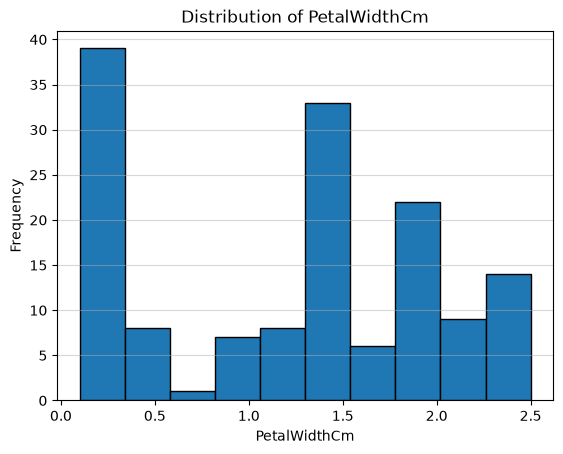

In [25]:
plt.Figure(figsize=(10,8))

plt.hist(df["PetalWidthCm"],bins=10,edgecolor="black")

plt.title("Distribution of PetalWidthCm")
plt.xlabel("PetalWidthCm")
plt.ylabel("Frequency")

plt.grid(axis="y",alpha=0.5)
plt.show()

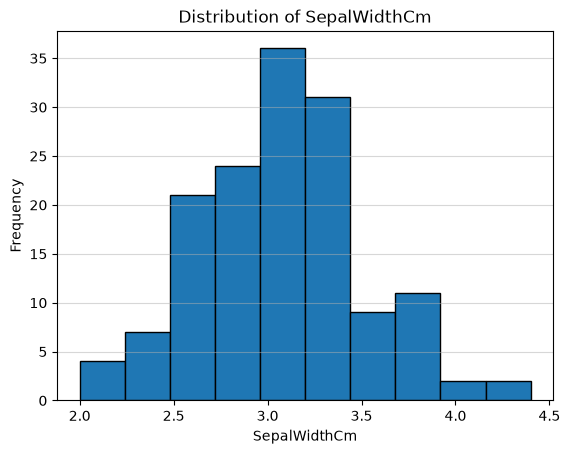

In [26]:
plt.Figure(figsize=(10,8))

plt.hist(df["SepalWidthCm"],bins=10,edgecolor="black")

plt.title("Distribution of SepalWidthCm")
plt.xlabel("SepalWidthCm")
plt.ylabel("Frequency")

plt.grid(axis="y",alpha=0.5)
plt.show()

## Kernel Density Estimation (KDE)

KDE provides a smoothed estimate of the distribution of a numerical
variable.

It helps us examine the distribution shape without relying only
on histogram bin boundaries.

In [28]:
numerical_column=df.select_dtypes(include="number").columns
numerical_column

Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'], dtype='str')

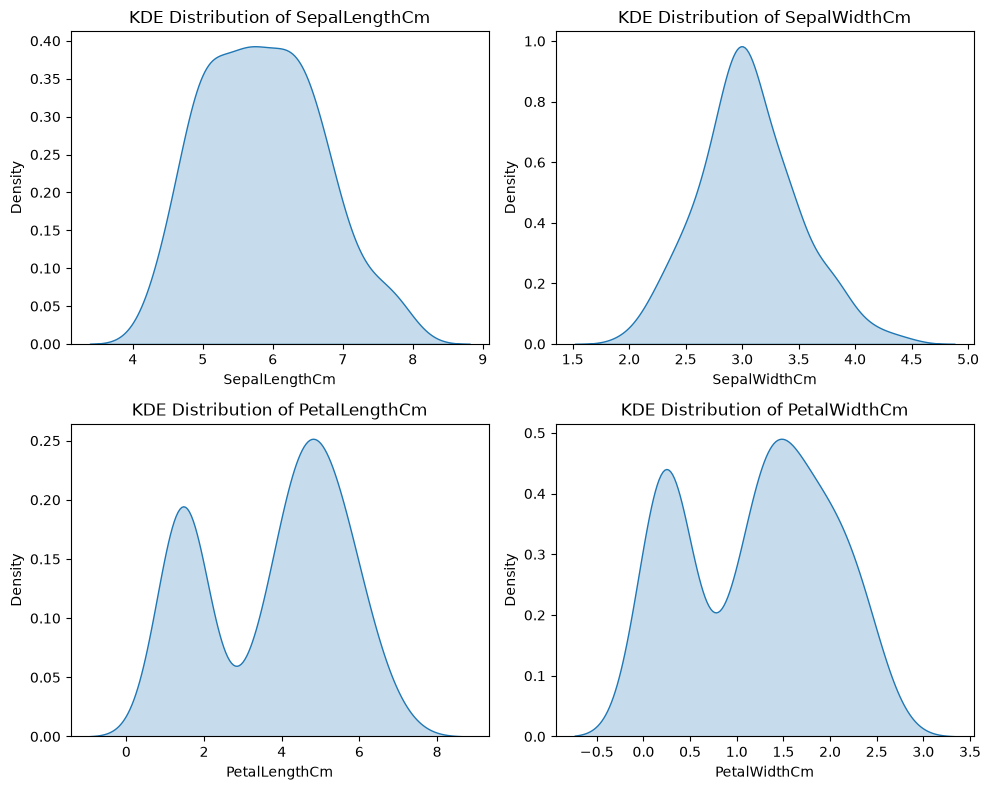

In [41]:
fig,axes=plt.subplots(2,2,figsize=(10,8))

for column,ax in zip(numerical_column,axes.flatten()):

    sns.kdeplot(data=df , 
                x=column ,
                fill=True ,
                ax=ax
                )

    ax.set_title(f"KDE Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()



Corelation

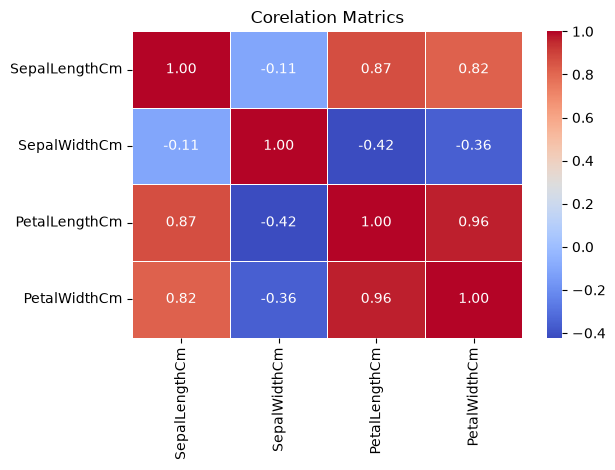

In [45]:
corelation=df[numerical_column].corr()

plt.Figure(figsize=(10,6))

sns.heatmap(
    corelation ,
    annot=True,
    fmt=".2f" ,
    cmap="coolwarm" ,
    linewidths=0.5
)

plt.title("Corelation Matrics")
plt.tight_layout()
plt.show()


Pair plot

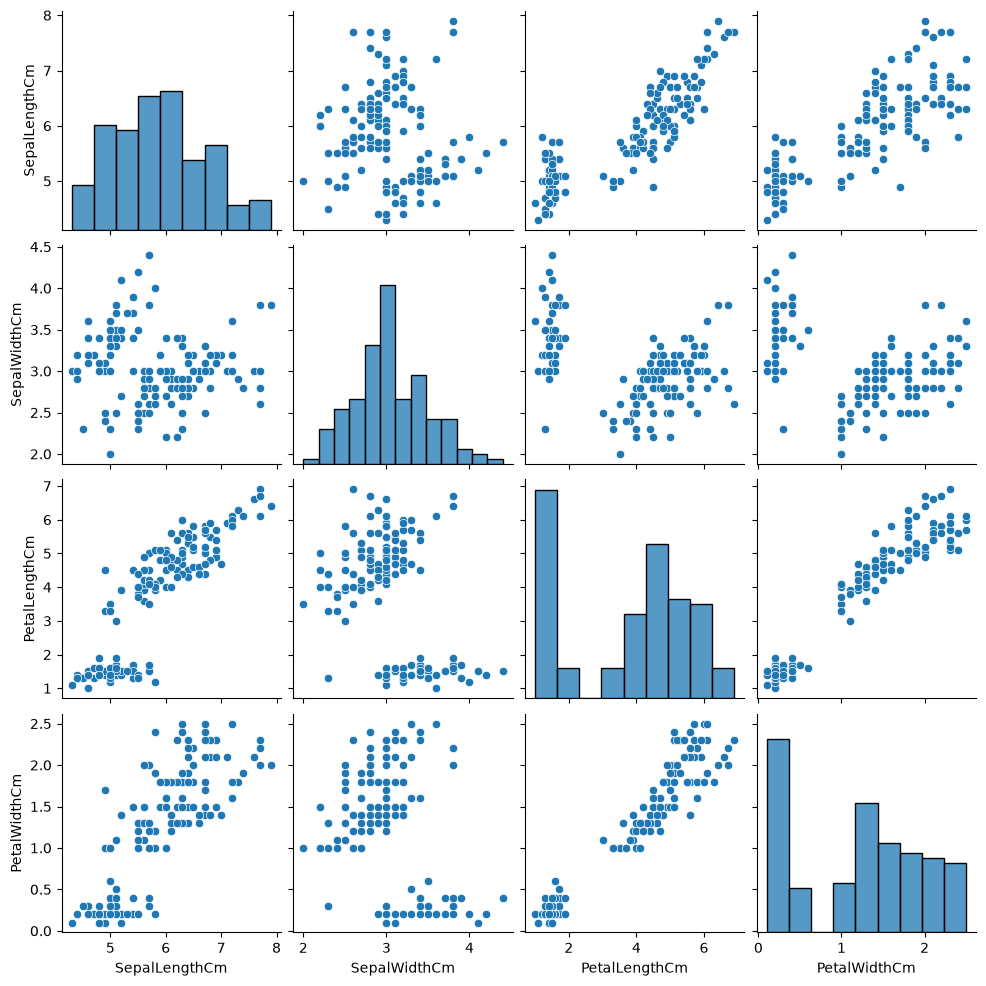

In [47]:

sns.pairplot(
    df[numerical_column] ,
    diag_kind="hist"
)

plt.show()

Box Plot

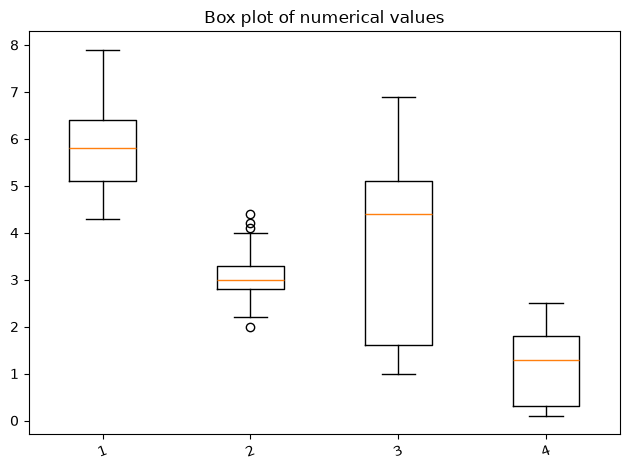

In [49]:
plt.Figure(figsize=(10,8))

plt.boxplot(
    df[numerical_column]
)

plt.title("Box plot of numerical values")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()